In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
file_path = "../data/processed/delhi_diesel_processed.csv"

df = pd.read_csv(file_path)

df.head()

,date,city,diesel_price,previous_diesel_price,diesel_price_change,diesel_return,log_return,diesel_ma_7,diesel_ma_30,volatility_7d,volatility_30d,momentum_7d,momentum_30d,price_vs_ma_7,price_vs_ma_30,target_next_day_diesel_price,target_next_day_change
0,2017-07-16,Delhi,54.93,54.85,0.08,0.001459,0.001457,54.738571,53.971667,0.002139,0.002401,0.011230,0.008075,0.003497,0.017756,54.99,0.06
1,2017-07-17,Delhi,54.99,54.93,0.06,0.001092,0.001092,54.801429,53.994000,0.001796,0.002318,0.008066,0.012334,0.003441,0.018446,55.04,0.05
2,2017-07-18,Delhi,55.04,54.99,0.05,0.000909,0.000909,54.844286,54.024000,0.001473,0.002209,0.005480,0.016624,0.003569,0.018806,55.04,0.00
3,2017-07-19,Delhi,55.04,55.04,0.00,0.000000,0.000000,54.887143,54.058333,0.001473,0.002141,0.005480,0.019071,0.002785,0.018159,55.05,0.01
4,2017-07-20,Delhi,55.05,55.04,0.01,0.000182,0.000182,54.937143,54.094667,0.001352,0.002123,0.006399,0.020200,0.002054,0.017660,55.02,-0.03


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Info:")
df.info()

Shape: (3341, 17)

Columns:
['date', 'city', 'diesel_price', 'previous_diesel_price', 'diesel_price_change', 'diesel_return', 'log_return', 'diesel_ma_7', 'diesel_ma_30', 'volatility_7d', 'volatility_30d', 'momentum_7d', 'momentum_30d', 'price_vs_ma_7', 'price_vs_ma_30', 'target_next_day_diesel_price', 'target_next_day_change']

Data Types:
date                             object
city                             object
diesel_price                    float64
previous_diesel_price           float64
diesel_price_change             float64
diesel_return                   float64
log_return                      float64
diesel_ma_7                     float64
diesel_ma_30                    float64
volatility_7d                   float64
volatility_30d                  float64
momentum_7d                     float64
momentum_30d                    float64
price_vs_ma_7                   float64
price_vs_ma_30                  float64
target_next_day_diesel_price    float64
target_next_day_c

In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Start Date: 2017-07-16 00:00:00
End Date: 2026-09-07 00:00:00


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
date                            0
city                            0
diesel_price                    0
previous_diesel_price           0
diesel_price_change             0
diesel_return                   0
log_return                      0
diesel_ma_7                     0
diesel_ma_30                    0
volatility_7d                   0
volatility_30d                  0
momentum_7d                     0
momentum_30d                    0
price_vs_ma_7                   0
price_vs_ma_30                  0
target_next_day_diesel_price    0
target_next_day_change          0
dtype: int64

Total Missing Values: 0


In [6]:
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Dates:", df["date"].duplicated().sum())

Duplicate Rows: 0
Duplicate Dates: 0


In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,3341,2022-02-10 00:00:00,2017-07-16 00:00:00,2019-10-29 00:00:00,2022-02-10 00:00:00,2024-05-25 00:00:00,2026-09-07 00:00:00,NaN
diesel_price,3341.0,80.155055,54.93,67.82,87.62,89.62,98.42,11.463428
previous_diesel_price,3341.0,80.142978,54.85,67.79,87.62,89.62,98.42,11.468827
diesel_price_change,3341.0,0.012077,-11.75,0.0,0.0,0.0,7.1,0.340136
diesel_return,3341.0,0.000174,-0.119386,0.0,0.0,0.0,0.113983,0.004118
log_return,3341.0,0.000165,-0.127136,0.0,0.0,0.0,0.107942,0.004195
diesel_ma_7,3341.0,80.118721,54.738571,67.761429,87.62,89.62,97.92,11.473038
diesel_ma_30,3341.0,79.976489,53.971667,67.703667,87.62,89.62,96.67,11.506147
volatility_7d,3341.0,0.000925,0.0,0.0,0.0,0.000857,0.046059,0.003848
volatility_30d,3341.0,0.001623,0.0,0.0,0.000415,0.001583,0.022348,0.003696


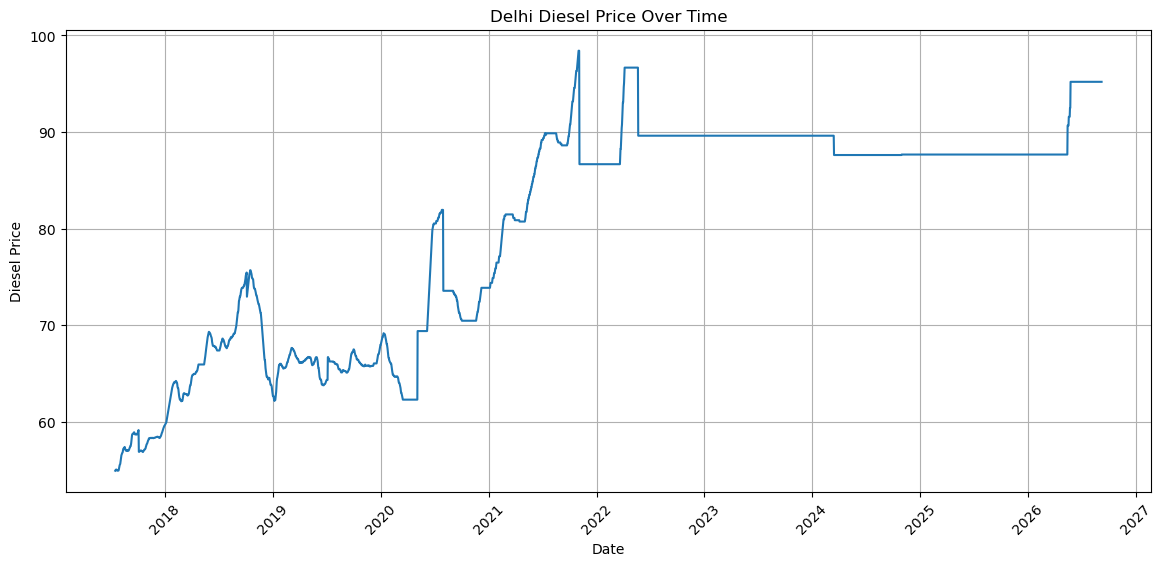

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["diesel_price"]
)

plt.title("Delhi Diesel Price Over Time")
plt.xlabel("Date")
plt.ylabel("Diesel Price")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

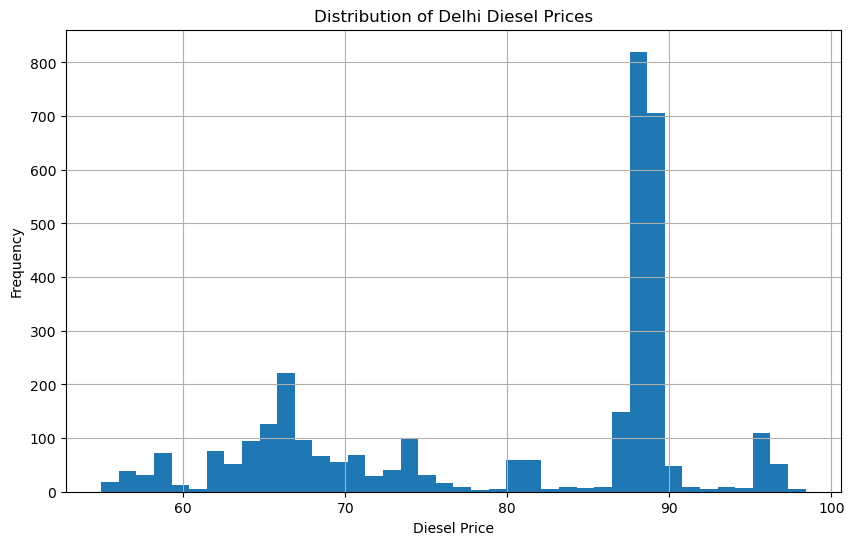

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["diesel_price"].dropna(),
    bins=40
)

plt.title("Distribution of Delhi Diesel Prices")
plt.xlabel("Diesel Price")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

In [10]:
change_columns = [
    col for col in df.columns
    if "change" in col.lower()
]

print("Change Columns:")
print(change_columns)

Change Columns:
['diesel_price_change', 'target_next_day_change']


In [11]:
if "diesel_price_change" in df.columns:
    change_col = "diesel_price_change"
elif "daily_price_change" in df.columns:
    change_col = "daily_price_change"
else:
    change_col = change_columns[0]

print("Selected Change Column:", change_col)

Selected Change Column: diesel_price_change


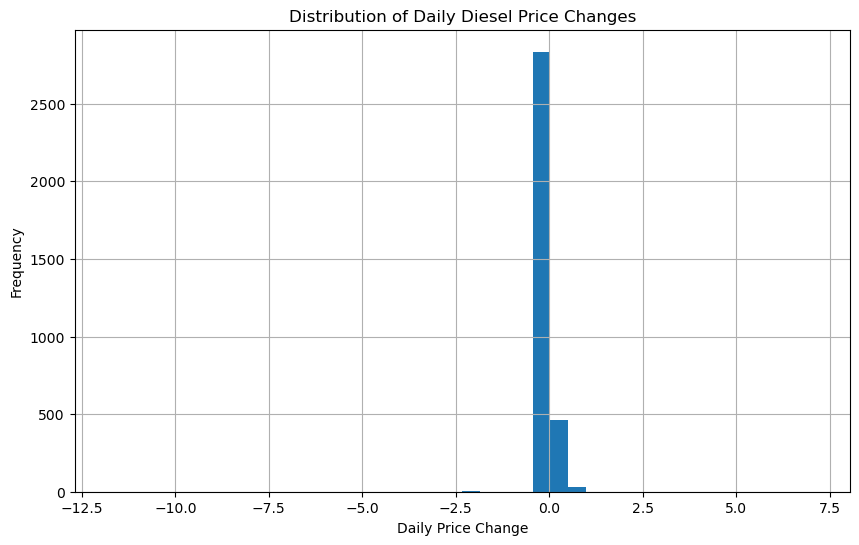

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    df[change_col].dropna(),
    bins=40
)

plt.title("Distribution of Daily Diesel Price Changes")
plt.xlabel("Daily Price Change")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

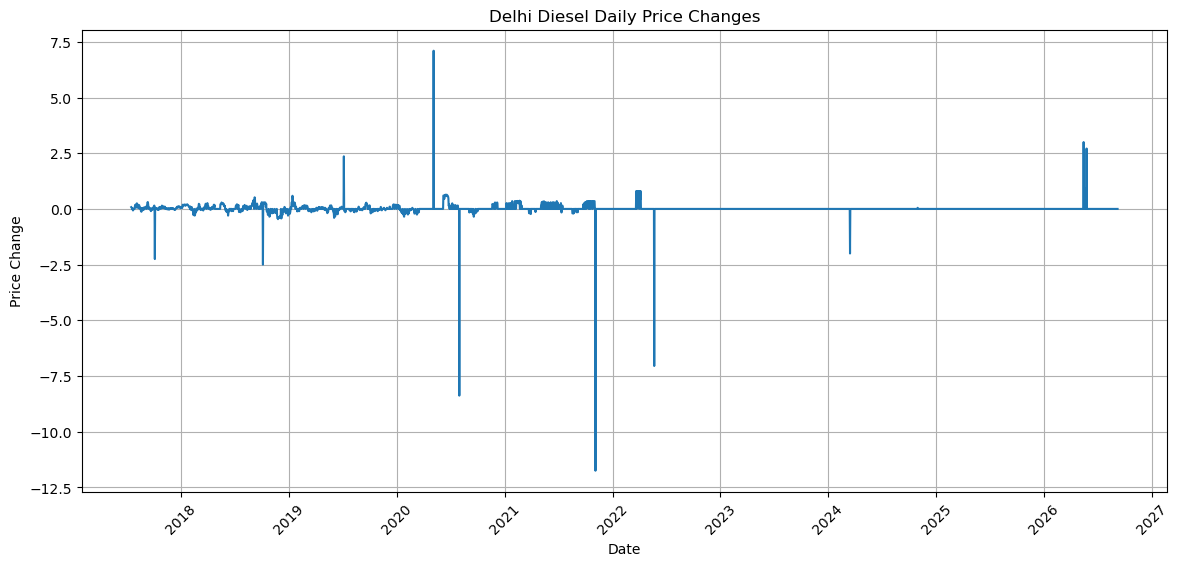

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df[change_col]
)

plt.title("Delhi Diesel Daily Price Changes")
plt.xlabel("Date")
plt.ylabel("Price Change")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

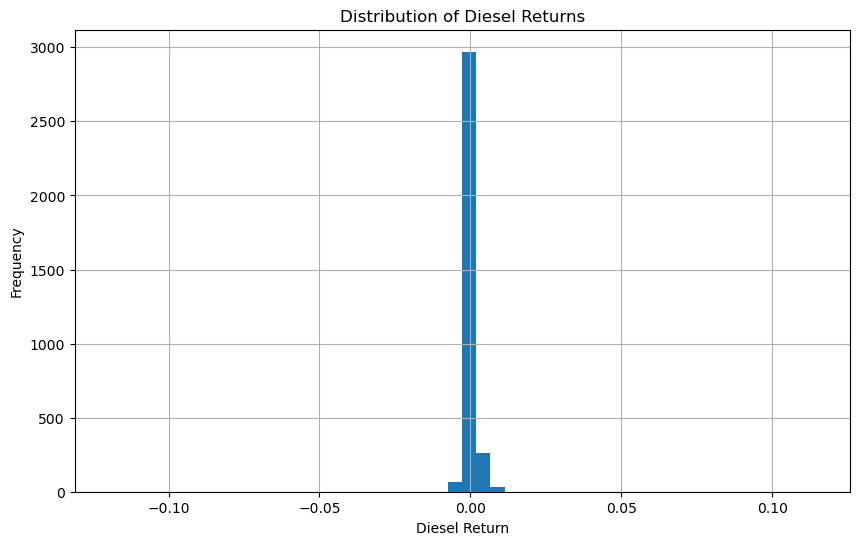

In [14]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["diesel_return"].dropna(),
    bins=50
)

plt.title("Distribution of Diesel Returns")
plt.xlabel("Diesel Return")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

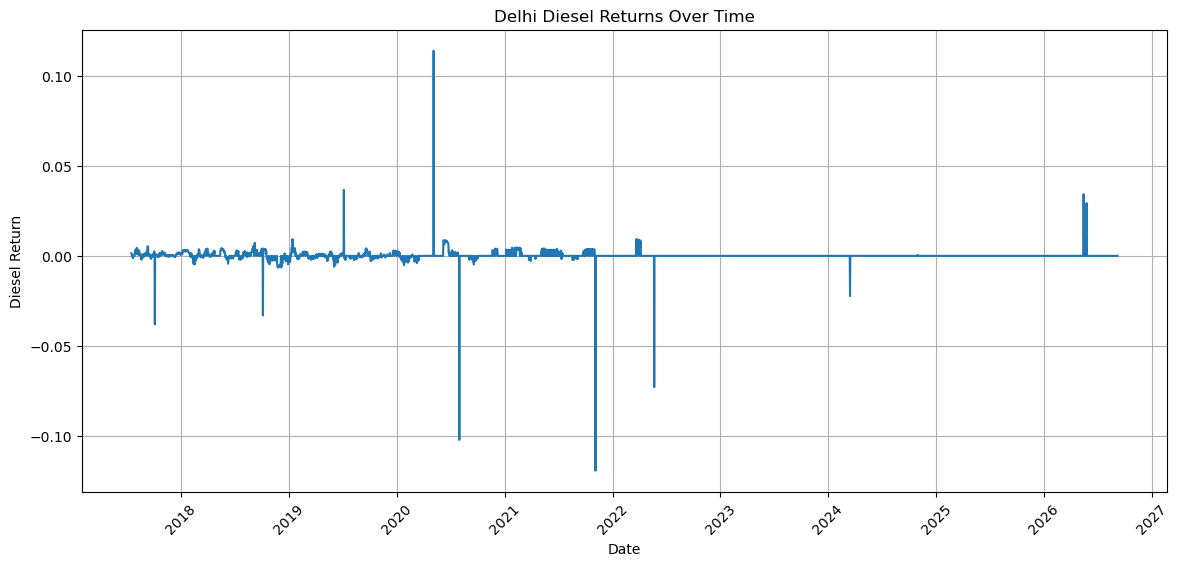

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["diesel_return"]
)

plt.title("Delhi Diesel Returns Over Time")
plt.xlabel("Date")
plt.ylabel("Diesel Return")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [16]:
print("Mean Return:", df["diesel_return"].mean())
print("Median Return:", df["diesel_return"].median())
print("Standard Deviation:", df["diesel_return"].std())
print("Minimum Return:", df["diesel_return"].min())
print("Maximum Return:", df["diesel_return"].max())

Mean Return: 0.0001737290183645921
Median Return: 0.0
Standard Deviation: 0.004117936509757867
Minimum Return: -0.1193863035968298
Maximum Return: 0.1139829828222829


In [17]:
volatility_columns = [
    col for col in df.columns
    if "volatility" in col.lower()
]

print("Volatility Columns:")
print(volatility_columns)

Volatility Columns:
['volatility_7d', 'volatility_30d']


In [18]:
if "volatility_30d" in df.columns:
    volatility_col = "volatility_30d"
elif "volatility_7d" in df.columns:
    volatility_col = "volatility_7d"
else:
    volatility_col = volatility_columns[-1]

print("Selected Volatility Column:", volatility_col)

Selected Volatility Column: volatility_30d


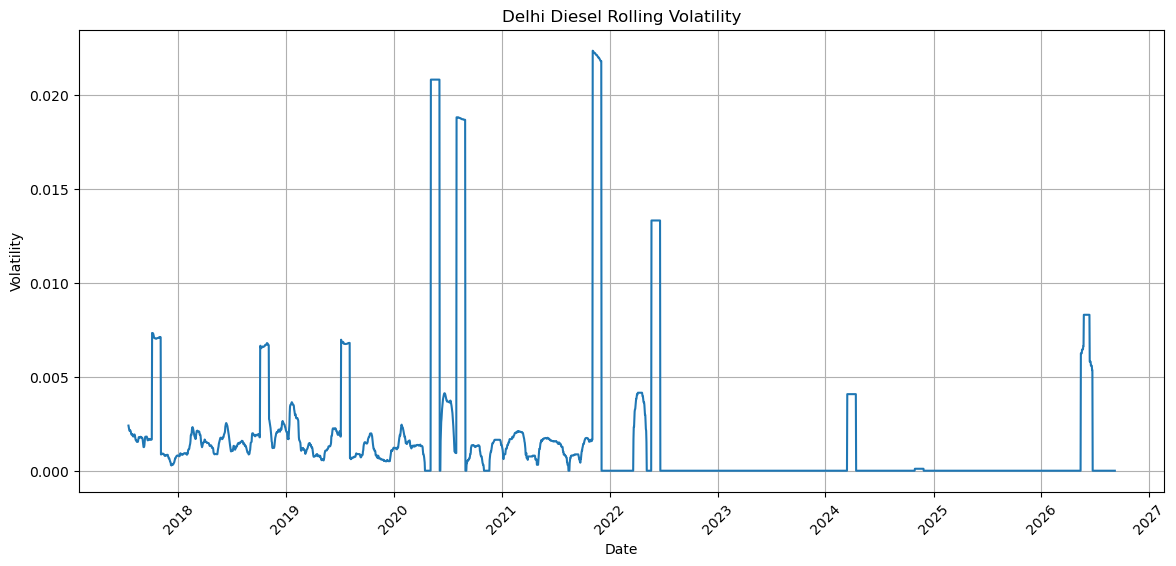

In [19]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df[volatility_col]
)

plt.title("Delhi Diesel Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [20]:
df[volatility_col].describe()

count    3341.000000
mean        0.001623
std         0.003696
min         0.000000
25%         0.000000
50%         0.000415
75%         0.001583
max         0.022348
Name: volatility_30d, dtype: float64

In [21]:
highest_volatility = (
    df[["date", volatility_col]]
    .sort_values(
        by=volatility_col,
        ascending=False
    )
    .head(10)
)

highest_volatility

,date,volatility_30d
1572,2021-11-04,0.022348
1573,2021-11-05,0.022328
1574,2021-11-06,0.022307
1575,2021-11-07,0.022286
1576,2021-11-08,0.022264
1577,2021-11-09,0.022241
1578,2021-11-10,0.022218
1579,2021-11-11,0.022218
1580,2021-11-12,0.022218
1581,2021-11-13,0.022194


In [22]:
ma_columns = [
    col for col in df.columns
    if "diesel_ma" in col.lower()
]

print("Moving Average Columns:")
print(ma_columns)

Moving Average Columns:
['diesel_ma_7', 'diesel_ma_30']


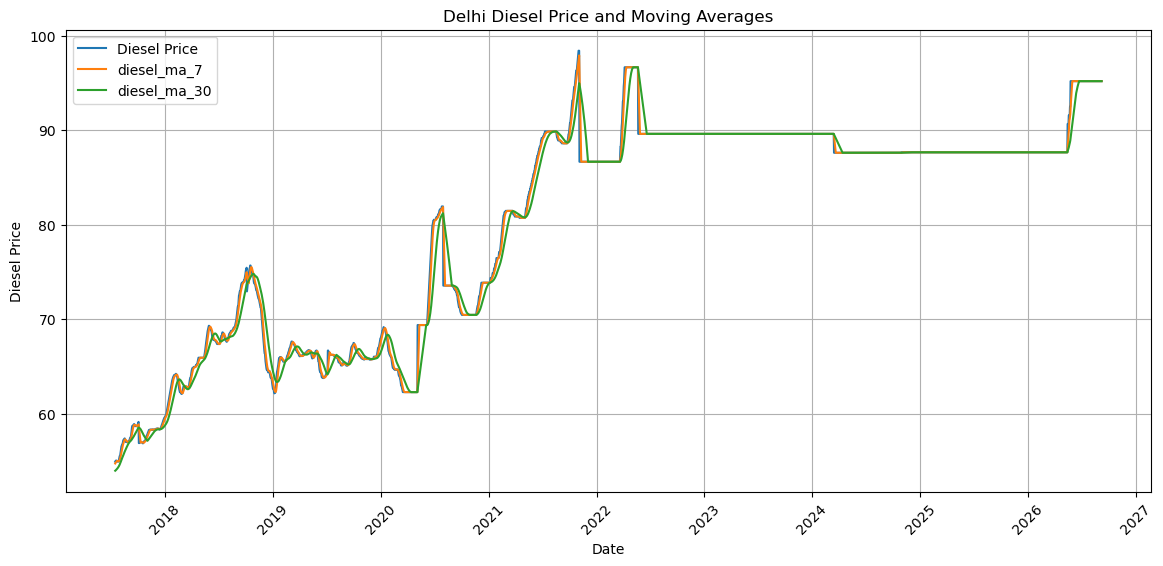

In [23]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["diesel_price"],
    label="Diesel Price"
)

for col in ma_columns:
    plt.plot(
        df["date"],
        df[col],
        label=col
    )

plt.title("Delhi Diesel Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Diesel Price")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [24]:
momentum_columns = [
    col for col in df.columns
    if "momentum" in col.lower()
]

print("Momentum Columns:")
print(momentum_columns)

Momentum Columns:
['momentum_7d', 'momentum_30d']


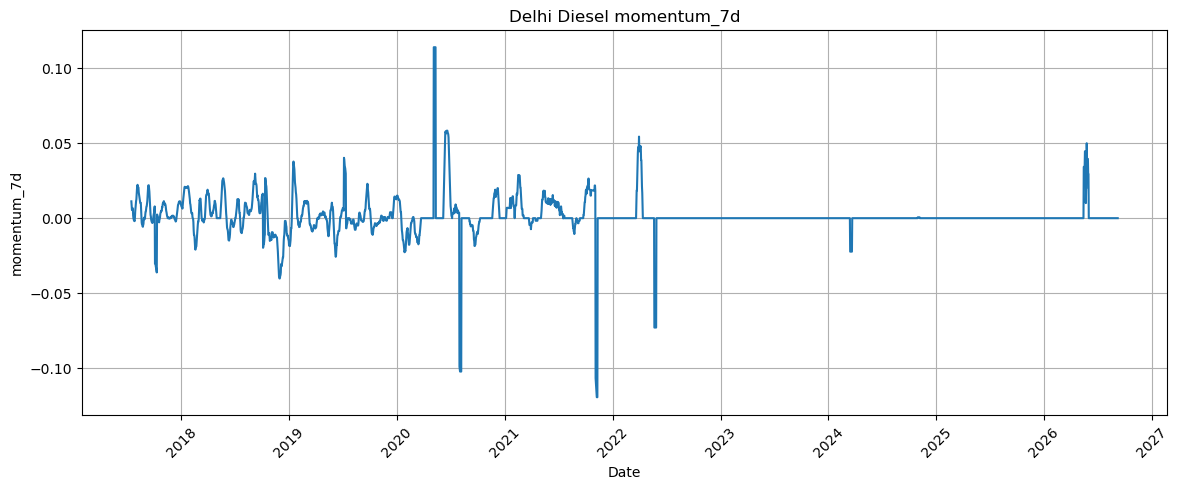

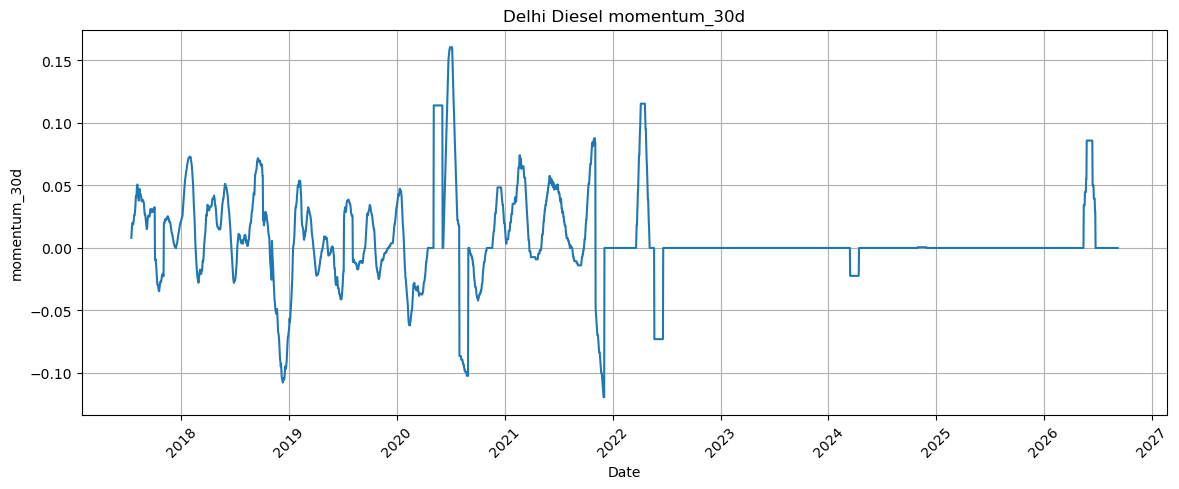

In [25]:
for col in momentum_columns:

    plt.figure(figsize=(14, 5))

    plt.plot(
        df["date"],
        df[col]
    )

    plt.title(f"Delhi Diesel {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()

In [26]:
price_ma_columns = [
    col for col in df.columns
    if "price_vs_ma" in col.lower()
]

print("Price vs MA Columns:")
print(price_ma_columns)

Price vs MA Columns:
['price_vs_ma_7', 'price_vs_ma_30']


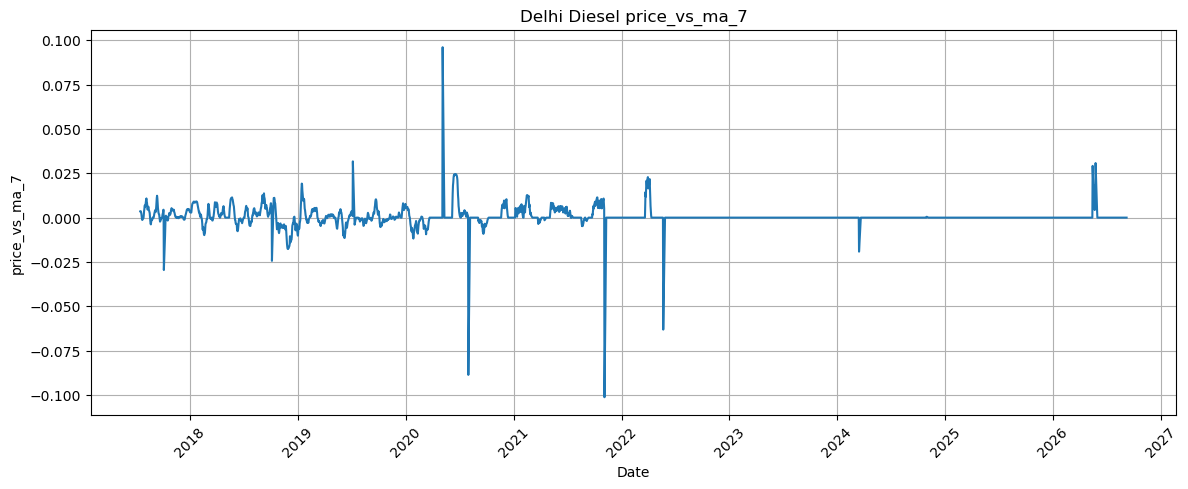

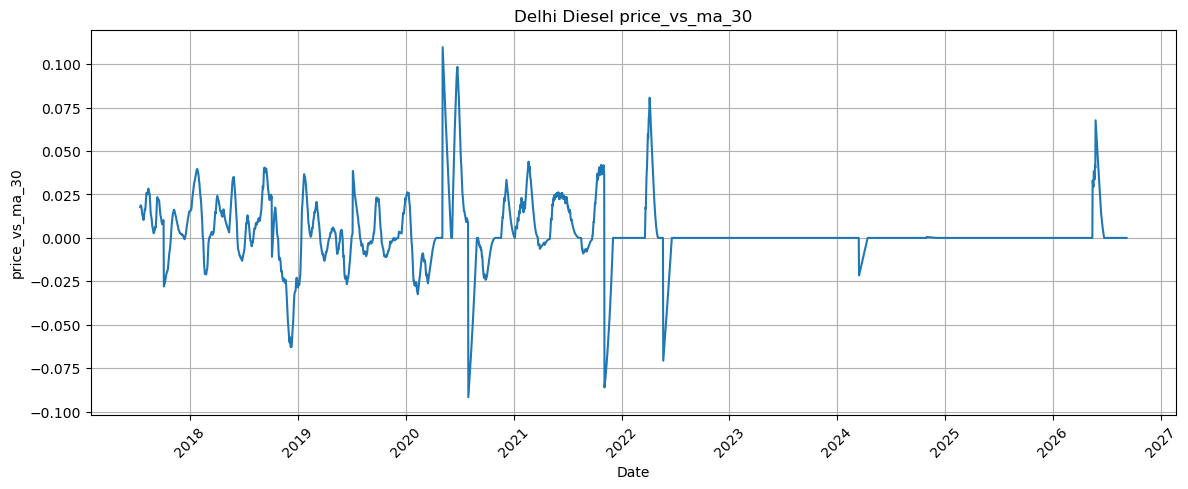

In [27]:
for col in price_ma_columns:

    plt.figure(figsize=(14, 5))

    plt.plot(
        df["date"],
        df[col]
    )

    plt.title(f"Delhi Diesel {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()

In [28]:
target_columns = [
    col for col in df.columns
    if "target_next_day" in col.lower()
]

print("Target Columns:")
print(target_columns)

Target Columns:
['target_next_day_diesel_price', 'target_next_day_change']


In [29]:
if "target_next_day_diesel_price" in df.columns:
    target_col = "target_next_day_diesel_price"
elif "target_next_day_change" in df.columns:
    target_col = "target_next_day_change"
else:
    target_col = target_columns[0]

print("Selected Target:", target_col)

print("\nTarget Statistics:")
print(df[target_col].describe())

Selected Target: target_next_day_diesel_price

Target Statistics:
count    3341.000000
mean       80.167109
std        11.458067
min        54.930000
25%        67.820000
50%        87.620000
75%        89.620000
max        98.420000
Name: target_next_day_diesel_price, dtype: float64


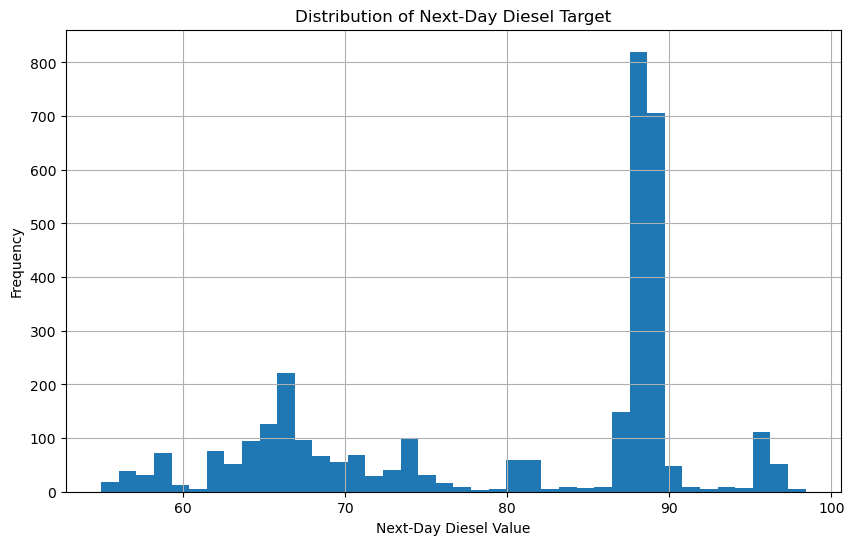

In [30]:
plt.figure(figsize=(10, 6))

plt.hist(
    df[target_col].dropna(),
    bins=40
)

plt.title("Distribution of Next-Day Diesel Target")
plt.xlabel("Next-Day Diesel Value")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

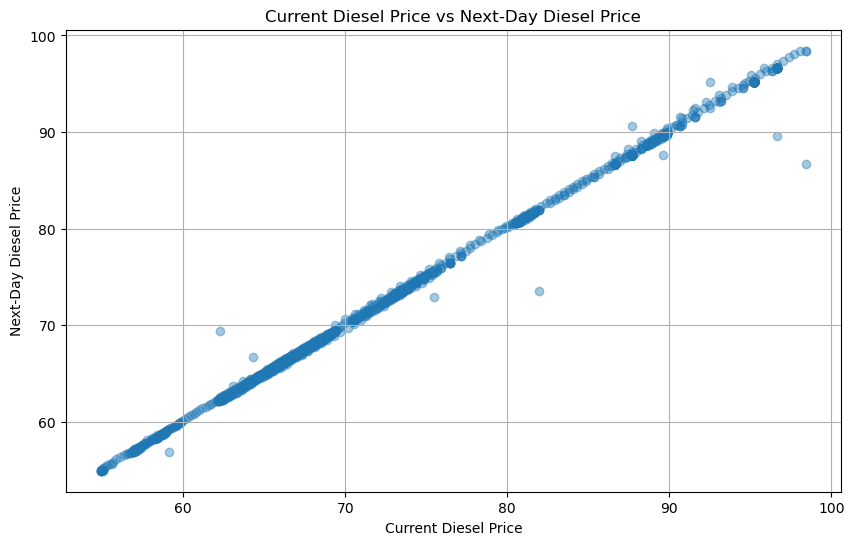

In [31]:
if "target_next_day_diesel_price" in df.columns:

    plt.figure(figsize=(10, 6))

    plt.scatter(
        df["diesel_price"],
        df["target_next_day_diesel_price"],
        alpha=0.4
    )

    plt.title("Current Diesel Price vs Next-Day Diesel Price")
    plt.xlabel("Current Diesel Price")
    plt.ylabel("Next-Day Diesel Price")
    plt.grid(True)

    plt.show()

In [32]:
corr = df.corr(numeric_only=True)

target_correlations = (
    corr[target_col]
    .sort_values(ascending=False)
)

target_correlations

target_next_day_diesel_price    1.000000
diesel_price                    0.999560
previous_diesel_price           0.999056
diesel_ma_7                     0.998373
diesel_ma_30                    0.991546
momentum_30d                    0.013125
price_vs_ma_30                  0.005985
diesel_price_change             0.001134
target_next_day_change         -0.000923
momentum_7d                    -0.006319
log_return                     -0.007016
diesel_return                  -0.007532
price_vs_ma_7                  -0.008272
volatility_7d                  -0.097341
volatility_30d                 -0.161629
Name: target_next_day_diesel_price, dtype: float64

In [33]:
strongest_features = (
    target_correlations
    .drop(target_col)
    .sort_values(
        key=abs,
        ascending=False
    )
)

print("Strongest Feature Correlations:")
print(strongest_features.head(15))

Strongest Feature Correlations:
diesel_price              0.999560
previous_diesel_price     0.999056
diesel_ma_7               0.998373
diesel_ma_30              0.991546
volatility_30d           -0.161629
volatility_7d            -0.097341
momentum_30d              0.013125
price_vs_ma_7            -0.008272
diesel_return            -0.007532
log_return               -0.007016
momentum_7d              -0.006319
price_vs_ma_30            0.005985
diesel_price_change       0.001134
target_next_day_change   -0.000923
Name: target_next_day_diesel_price, dtype: float64


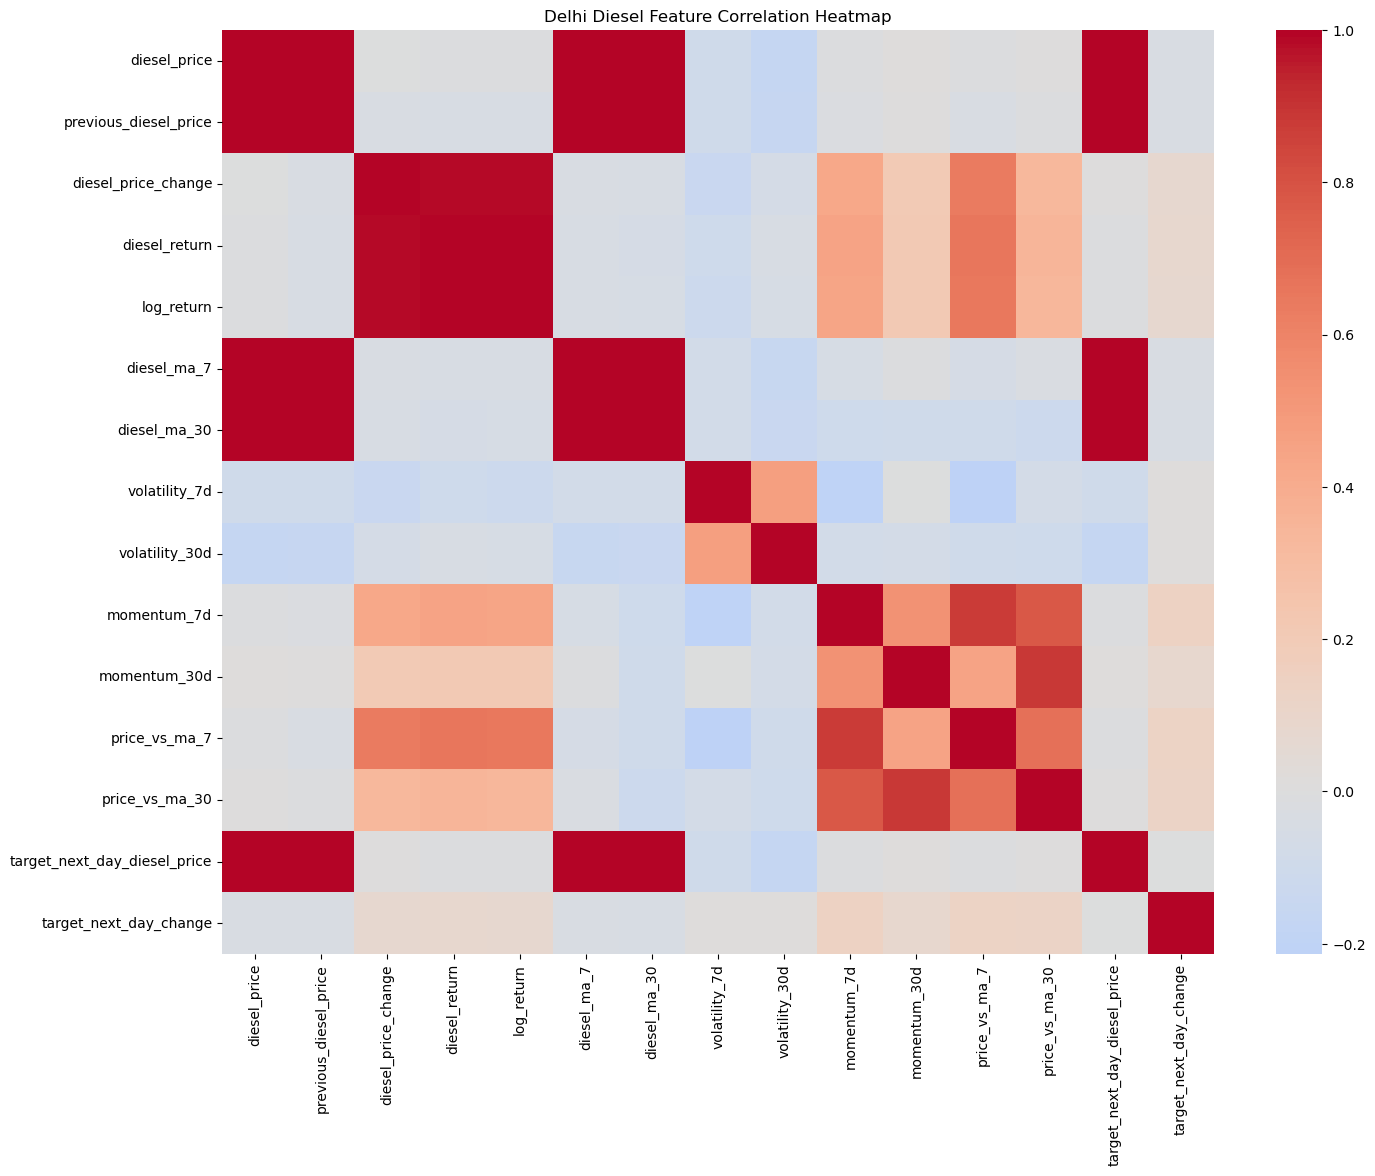

In [34]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Delhi Diesel Feature Correlation Heatmap")

plt.show()

In [35]:
extreme_changes = (
    df[
        [
            "date",
            "diesel_price",
            change_col,
            "diesel_return"
        ]
    ]
    .sort_values(
        by="diesel_return",
        key=abs,
        ascending=False
    )
    .head(15)
)

extreme_changes

,date,diesel_price,diesel_price_change,diesel_return
1572,2021-11-04,86.67,-11.75,-0.119386
1024,2020-05-05,69.39,7.10,0.113983
1111,2020-07-31,73.56,-8.38,-0.102270
1771,2022-05-22,89.62,-7.05,-0.072929
80,2017-10-04,56.89,-2.25,-0.038045
720,2019-07-06,66.69,2.36,0.036686
3225,2026-05-15,90.67,3.00,0.034219
446,2018-10-05,72.95,-2.50,-0.033135
3235,2026-05-25,95.20,2.71,0.029300
2434,2024-03-15,87.62,-2.00,-0.022316


In [36]:
print("Lowest Diesel Price:")
print(
    df.loc[
        df["diesel_price"].idxmin(),
        ["date", "diesel_price"]
    ]
)

print("\nHighest Diesel Price:")
print(
    df.loc[
        df["diesel_price"].idxmax(),
        ["date", "diesel_price"]
    ]
)

Lowest Diesel Price:
date            2017-07-16 00:00:00
diesel_price                  54.93
Name: 0, dtype: object

Highest Diesel Price:
date            2021-11-01 00:00:00
diesel_price                  98.42
Name: 1569, dtype: object


In [37]:
print("FINAL DATA QUALITY CHECK")
print("------------------------")

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Dates:", df["date"].duplicated().sum())

print("Date Start:", df["date"].min())
print("Date End:", df["date"].max())

FINAL DATA QUALITY CHECK
------------------------
Rows: 3341
Columns: 17
Missing Values: 0
Duplicate Rows: 0
Duplicate Dates: 0
Date Start: 2017-07-16 00:00:00
Date End: 2026-09-07 00:00:00


In [38]:
summary = {
    "rows": len(df),
    "columns": len(df.columns),
    "date_start": df["date"].min(),
    "date_end": df["date"].max(),
    "missing_values": df.isnull().sum().sum(),
    "duplicate_rows": df.duplicated().sum(),
    "mean_diesel_price": df["diesel_price"].mean(),
    "min_diesel_price": df["diesel_price"].min(),
    "max_diesel_price": df["diesel_price"].max(),
    "mean_diesel_return": df["diesel_return"].mean(),
    "return_std": df["diesel_return"].std(),
    "mean_volatility": df[volatility_col].mean(),
    "max_volatility": df[volatility_col].max()
}

summary_df = pd.DataFrame([summary])

summary_df

,rows,columns,date_start,date_end,missing_values,duplicate_rows,mean_diesel_price,min_diesel_price,max_diesel_price,mean_diesel_return,return_std,mean_volatility,max_volatility
0,3341,17,2017-07-16,2026-09-07,0,0,80.155055,54.93,98.42,0.000174,0.004118,0.001623,0.022348


In [39]:
output_path = "../data/processed/delhi_diesel_eda_summary.csv"

summary_df.to_csv(
    output_path,
    index=False
)

print("EDA summary saved successfully!")
print(output_path)

EDA summary saved successfully!
../data/processed/delhi_diesel_eda_summary.csv
